First five rows:
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]

Dataset shape: (5172, 3002)

Missing values:

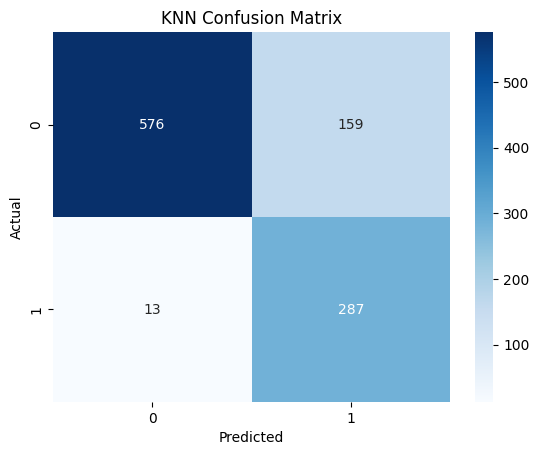


========== SVM ==========
Accuracy (%) : 95.07 %
Precision: 0.9136
Recall   : 0.9167
F1 Score : 0.9151

Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.97      0.96      0.97       735
        Spam       0.91      0.92      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035

Confusion Matrix:
[[709  26]
 [ 25 275]]


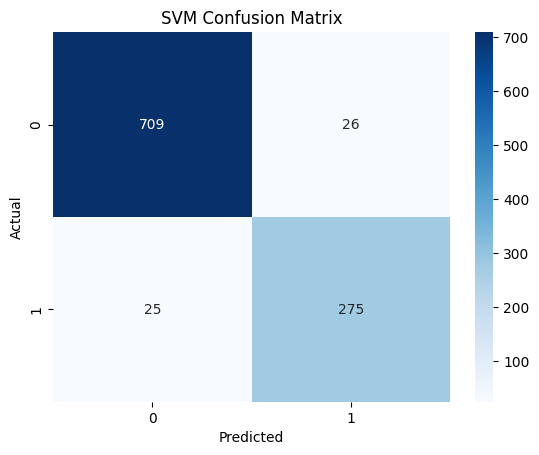


Model Comparison:
Model  Accuracy (%)  Precision  Recall  F1 Score
  KNN         83.38     0.6435  0.9567    0.7694
  SVM         95.07     0.9136  0.9167    0.9151


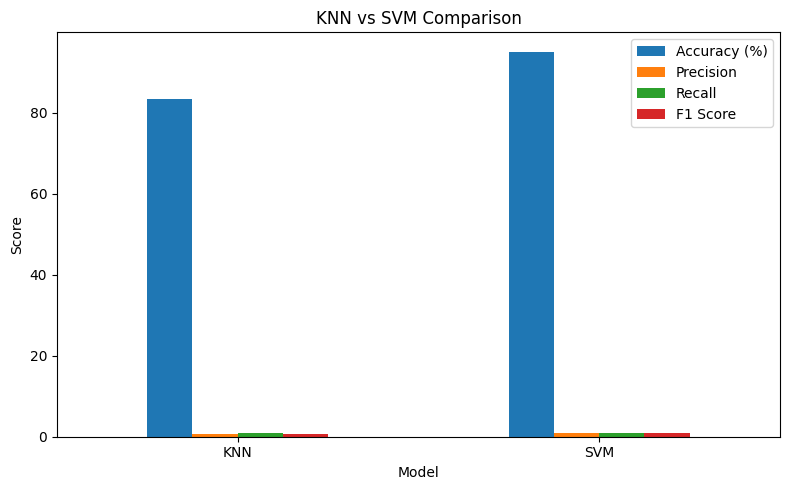

Best Model: SVM

Email Spam Classification Completed!


In [4]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 1. Load dataset
df = pd.read_csv("emails.csv")

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nMissing values:", df.isnull().sum().sum())

# 2. Preprocess dataset
df.columns = df.columns.str.strip()
df = df.drop_duplicates()
df = df.dropna()

# 3. Separate features and target
# Prediction: 0 = Not Spam, 1 = Spam

y = df["Prediction"].astype(int)

# Remove target and email identifier
X = df.drop(columns=["Prediction", "Email No."],
            errors="ignore")

# Keep only numerical features
X = X.select_dtypes(include="number")

print("\nNumber of features:", X.shape[1])
print("\nClass distribution:")
print(y.value_counts())

# 4. Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# 5. Create KNN and SVM models
models = {
    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="linear")
    )
}

# 6. Train and evaluate models
results = []

for name, model in models.items():

    print("\n==========", name, "==========")

    # Train model
    model.fit(X_train, y_train)

    # Predict test data
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    print("Accuracy (%) :", round(accuracy * 100, 2), "%")
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Not Spam", "Spam"],
        zero_division=0
    ))

    # Confusion matrix
    cm = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    )

    print("Confusion Matrix:")
    print(cm)

    # Store results
    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy * 100, 2),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1 Score": round(f1, 4)
    })

    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()



# 8. Compare KNN and SVM
comparison = pd.DataFrame(results)

print("\nModel Comparison:")
print(comparison.to_string(index=False))

# 9. Plot comparison graph
comparison.plot(
    x="Model",
    y=["Accuracy (%)", "Precision", "Recall", "F1 Score"],
    kind="bar",
    figsize=(8, 5)
)

plt.title("KNN vs SVM Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 10. Find the best model
if comparison.loc[0, "F1 Score"] > comparison.loc[1, "F1 Score"]:
    print("Best Model: KNN")
elif comparison.loc[0, "F1 Score"] < comparison.loc[1, "F1 Score"]:
    print("Best Model: SVM")
else:
    print("Both models have equal F1 Score.")

print("\nEmail Spam Classification Completed!")